# Assignment 1 – Task 1: MLPs and CNNs on Fashion-MNIST, transfer to CIFAR-10

**How to use this notebook**
1. On Colab: Runtime → Change runtime type → **T4 GPU**. With `USE_DRIVE = True`, datasets and results are stored in `MyDrive/IDL_A1/`, so CIFAR-10 is downloaded only once.
2. `QUICK_RUN = True` runs a short sample (small subset, few epochs). It only checks the pipeline; its numbers mean nothing.
3. `QUICK_RUN = False` runs the real experiments. **Every finished run is appended to `runs.jsonl` on Drive**. If Colab disconnects, run everything again and completed runs are skipped. Set `RUN_BUDGET = 40` (for example) to stop after 40 new runs, then re-run to do the next chunk.

Structure:
0. Setup & config
1. Data (90/10 train/validation split, test set kept aside)
2. Models, weight init, optimizers
3. Training loop with early stopping, plus the persistent run store
4. MNIST warm-up
5. One-factor-at-a-time sweep on Fashion-MNIST (MLP and CNN), several seeds per config
6. Top-k per model type → Fashion-MNIST test results
7. The selected setups on CIFAR-10

All selection uses **validation accuracy averaged over seeds**. Test accuracy is computed for every run so nothing has to be re-trained, but it is hidden in the sweep tables and only shown for the selected configurations.

## 0. Setup & config

In [ ]:
QUICK_RUN = False          # True = short sample run; False = full experiments
RUN_MNIST_WARMUP = True   # short MNIST sanity check (section 4)
USE_DRIVE = True          # on Colab: keep data + results on Google Drive
RUN_BUDGET = None         # e.g. 40 -> stop after 40 *new* runs (re-run the notebook to continue)

In [ ]:
import json
import os
import random
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

IN_COLAB = "google.colab" in sys.modules
if USE_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/IDL_A1"
else:
    ROOT = "."

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    torch.backends.cudnn.benchmark = True
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
print("Device:", DEVICE, "| torch", torch.__version__, "| root:", os.path.abspath(ROOT))

DATA_DIR = f"{ROOT}/data"
OUT_DIR = f"{ROOT}/results_task1" + ("_quick" if QUICK_RUN else "")
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

SEED = 42                      # seed for the train/val split
BATCH_SIZE = 128

if QUICK_RUN:
    MAX_EPOCHS, PATIENCE = 3, 2
    CIFAR_MAX_EPOCHS, CIFAR_PATIENCE = 3, 2
    SWEEP_SEEDS = [42, 43]
    FINAL_SEEDS = [42, 43]
    TOP_K_PER_MODEL = 2
    TRAIN_SUBSET, VAL_SUBSET, TEST_SUBSET = 3000, 1000, 2000
else:
    MAX_EPOCHS, PATIENCE = 30, 5              # Fashion-MNIST: early stopping on val acc
    CIFAR_MAX_EPOCHS, CIFAR_PATIENCE = 50, 8
    SWEEP_SEEDS = [42, 43, 44]
    FINAL_SEEDS = [42, 43, 44]
    TOP_K_PER_MODEL = 3                       # top-3 MLPs AND top-3 CNNs go to CIFAR-10
    TRAIN_SUBSET = VAL_SUBSET = TEST_SUBSET = None


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda | torch 2.11.0+cu130 | root: /content/drive/MyDrive/IDL_A1


## 1. Data

Both datasets are small enough to load into memory as one tensor (and onto the GPU), which is much faster than a `DataLoader` with per-image transforms. Steps:
* scale pixels to [0, 1]
* shuffle the official training set with a fixed seed and hold out **10 %** as validation
* normalise per channel with the mean/std of the **training part only**. The printout checks that the training data then has mean ≈ 0 and std ≈ 1.

In [ ]:
DATASETS = {
    "mnist": torchvision.datasets.MNIST,
    "fashion_mnist": torchvision.datasets.FashionMNIST,
    "cifar10": torchvision.datasets.CIFAR10,
}


def _to_tensors(ds):
    x = torch.as_tensor(np.asarray(ds.data)).float().div(255.0)
    if x.ndim == 3:                # (N, H, W) grayscale -> (N, 1, H, W)
        x = x.unsqueeze(1)
    else:                          # (N, H, W, C) colour  -> (N, C, H, W)
        x = x.permute(0, 3, 1, 2).contiguous()
    y = torch.as_tensor(np.asarray(ds.targets)).long()
    return x, y


def load_dataset(name, val_fraction=0.1):
    cls = DATASETS[name]
    t0 = time.time()
    train_ds = cls(DATA_DIR, train=True, download=True)
    test_ds = cls(DATA_DIR, train=False, download=True)
    x_full, y_full = _to_tensors(train_ds)
    x_test, y_test = _to_tensors(test_ds)

    g = torch.Generator().manual_seed(SEED)
    perm = torch.randperm(len(x_full), generator=g)
    n_val = int(len(x_full) * val_fraction)
    val_idx, tr_idx = perm[:n_val], perm[n_val:]
    x_tr, y_tr = x_full[tr_idx], y_full[tr_idx]
    x_val, y_val = x_full[val_idx], y_full[val_idx]

    mean = x_tr.mean(dim=(0, 2, 3), keepdim=True)
    std = x_tr.std(dim=(0, 2, 3), keepdim=True)

    def prep(x, y, limit):
        if limit is not None:
            x, y = x[:limit], y[:limit]
        return ((x - mean) / std).to(DEVICE), y.to(DEVICE)

    data = {
        "name": name,
        "train": prep(x_tr, y_tr, TRAIN_SUBSET),
        "val": prep(x_val, y_val, VAL_SUBSET),
        "test": prep(x_test, y_test, TEST_SUBSET),
        "in_shape": tuple(x_tr.shape[1:]),
        "n_classes": len(train_ds.classes),
        "classes": list(train_ds.classes),
    }
    xt = data["train"][0]
    print(f"{name}: train {tuple(xt.shape)}, val {tuple(data['val'][0].shape)}, "
          f"test {tuple(data['test'][0].shape)}, classes={data['n_classes']} ({time.time() - t0:.0f}s)")
    print(f"  normalisation check (train): per-channel mean {xt.mean(dim=(0, 2, 3)).cpu().numpy().round(3)}, "
          f"std {xt.std(dim=(0, 2, 3)).cpu().numpy().round(3)}")
    return data


def iterate_batches(x, y, batch_size, shuffle):
    idx = torch.randperm(len(x), device=x.device) if shuffle else torch.arange(len(x), device=x.device)
    for i in range(0, len(x), batch_size):
        b = idx[i:i + batch_size]
        yield x[b], y[b]

fashion_mnist: train (54000, 1, 28, 28), val (6000, 1, 28, 28), test (10000, 1, 28, 28), classes=10 (1s)
  normalisation check (train): per-channel mean [0.], std [1.]


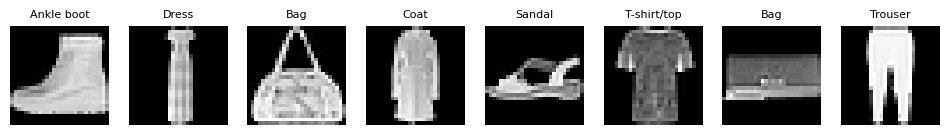

In [ ]:
fmnist = load_dataset("fashion_mnist")

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i, ax in enumerate(axes):
    ax.imshow(fmnist["train"][0][i, 0].cpu(), cmap="gray")
    ax.set_title(fmnist["classes"][fmnist["train"][1][i].item()], fontsize=8)
    ax.axis("off")
plt.show()

## 2. Models, initialisation, optimizers

* **MLP**: `Flatten → [Linear → activation → (Dropout)] × k → Linear`. Only fully connected layers, so it does not use the fact that neighbouring pixels are related.
* **CNN**: blocks of `[Conv2d → (BatchNorm) → activation] × m → MaxPool2d`, followed by a linear head. Works for any input shape (1×28×28 or 3×32×32) because the size of the flattened features is computed with a dummy forward pass.

In [ ]:
ACTIVATIONS = {
    "relu": nn.ReLU,
    "leaky_relu": lambda: nn.LeakyReLU(0.01),
    "gelu": nn.GELU,
    "elu": nn.ELU,
    "tanh": nn.Tanh,
    "sigmoid": nn.Sigmoid,
}


class MLP(nn.Module):
    def __init__(self, in_shape, n_classes, hidden=(512, 256), activation="relu", dropout=0.0):
        super().__init__()
        layers = [nn.Flatten()]
        d = int(np.prod(in_shape))
        for h in hidden:
            layers += [nn.Linear(d, h), ACTIVATIONS[activation]()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            d = h
        layers.append(nn.Linear(d, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class CNN(nn.Module):
    def __init__(self, in_shape, n_classes, channels=(32, 64), kernel_size=3, convs_per_block=1,
                 fc_hidden=128, activation="relu", dropout=0.0, batchnorm=False):
        super().__init__()
        act = ACTIVATIONS[activation]
        c = in_shape[0]
        blocks = []
        for out_c in channels:
            for _ in range(convs_per_block):
                blocks.append(nn.Conv2d(c, out_c, kernel_size, padding=kernel_size // 2))
                if batchnorm:
                    blocks.append(nn.BatchNorm2d(out_c))
                blocks.append(act())
                c = out_c
            blocks.append(nn.MaxPool2d(2))
        self.features = nn.Sequential(*blocks)

        self.features.eval()
        with torch.no_grad():
            flat = self.features(torch.zeros(1, *in_shape)).numel()
        self.features.train()

        head = [nn.Flatten()]
        if dropout > 0:
            head.append(nn.Dropout(dropout))
        if fc_hidden:
            head += [nn.Linear(flat, fc_hidden), act()]
            if dropout > 0:
                head.append(nn.Dropout(dropout))
            flat = fc_hidden
        head.append(nn.Linear(flat, n_classes))
        self.head = nn.Sequential(*head)

    def forward(self, x):
        return self.head(self.features(x))


def init_weights(model, scheme):
    """'default' keeps PyTorch's built-in init (Kaiming-uniform with a=sqrt(5))."""
    if scheme == "default":
        return
    for m in model.modules():
        if isinstance(m, (nn.Linear, nn.Conv2d)):
            if scheme == "xavier":
                nn.init.xavier_uniform_(m.weight)
            elif scheme == "kaiming":
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
            elif scheme == "normal":        # small fixed-std Gaussian
                nn.init.normal_(m.weight, mean=0.0, std=0.01)
            elif scheme == "zeros":         # symmetry is never broken -> network can't learn
                nn.init.zeros_(m.weight)
            else:
                raise ValueError(scheme)
            if m.bias is not None:
                nn.init.zeros_(m.bias)


def build_model(cfg, in_shape, n_classes):
    if cfg["model"] == "mlp":
        model = MLP(in_shape, n_classes, hidden=cfg["hidden"], activation=cfg["activation"],
                    dropout=cfg["dropout"])
    elif cfg["model"] == "cnn":
        model = CNN(in_shape, n_classes, channels=cfg["channels"], kernel_size=cfg["kernel_size"],
                    convs_per_block=cfg["convs_per_block"], fc_hidden=cfg["fc_hidden"],
                    activation=cfg["activation"], dropout=cfg["dropout"], batchnorm=cfg["batchnorm"])
    else:
        raise ValueError(cfg["model"])
    init_weights(model, cfg["init"])
    return model


def make_optimizer(cfg, params):
    name, lr, wd = cfg["optimizer"], cfg["lr"], cfg["weight_decay"]
    if name == "sgd":
        return torch.optim.SGD(params, lr=lr, weight_decay=wd)
    if name == "sgd_momentum":
        return torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=wd)
    if name == "adam":                      # weight_decay here = L2 penalty added to the gradient
        return torch.optim.Adam(params, lr=lr, weight_decay=wd)
    if name == "adamw":                     # decoupled weight decay
        return torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    if name == "rmsprop":
        return torch.optim.RMSprop(params, lr=lr, weight_decay=wd)
    raise ValueError(name)


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

## 3. Training loop and persistent run store

* Training runs for at most `max_epochs` and stops after `patience` epochs without a better validation accuracy. The best checkpoint is restored.
* Three accuracy curves are recorded per epoch:
  * `train_acc`: running average over the epoch, in train mode (dropout on, weights still changing). This is why it can sit *below* validation accuracy early on.
  * `train_acc_eval`: a fixed 10k-image training subset, evaluated in eval mode at the end of the epoch. This is directly comparable to validation, and `gap = train_acc_eval − val_acc` at the best epoch is the overfitting measure.
  * `val_acc`
* `no_learning` flags runs that stay near chance (e.g. `init=zeros`). This is a different failure from `diverged` (NaN/inf loss).

In [ ]:
@torch.no_grad()
def evaluate(model, x, y, batch_size=1024):
    model.eval()
    loss_sum, correct = 0.0, 0
    for xb, yb in iterate_batches(x, y, batch_size, shuffle=False):
        out = model(xb)
        loss_sum += F.cross_entropy(out, yb, reduction="sum").item()
        correct += (out.argmax(1) == yb).sum().item()
    return loss_sum / len(x), correct / len(x)


def train_model(cfg, data, max_epochs, patience, seed, verbose=False):
    set_seed(seed)
    model = build_model(cfg, data["in_shape"], data["n_classes"]).to(DEVICE)
    opt = make_optimizer(cfg, model.parameters())
    sched = (torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max_epochs)
             if cfg.get("scheduler") == "cosine" else None)
    x_tr, y_tr = data["train"]
    x_val, y_val = data["val"]
    n_eval = min(10000, len(x_tr))

    hist = {"train_loss": [], "train_acc": [], "train_acc_eval": [], "val_loss": [], "val_acc": []}
    best_acc, best_epoch, best_state = -1.0, 0, None
    diverged, bad_epochs = False, 0
    t0 = time.time()
    for ep in range(1, max_epochs + 1):
        model.train()
        loss_sum = torch.zeros((), device=DEVICE)
        correct = torch.zeros((), device=DEVICE)
        for xb, yb in iterate_batches(x_tr, y_tr, BATCH_SIZE, shuffle=True):
            opt.zero_grad()
            out = model(xb)
            loss = F.cross_entropy(out, yb)
            loss.backward()
            opt.step()
            loss_sum += loss.detach() * len(yb)
            correct += (out.argmax(1) == yb).sum()
        if sched is not None:
            sched.step()
        tr_loss, tr_acc = loss_sum.item() / len(x_tr), correct.item() / len(x_tr)
        _, tr_acc_eval = evaluate(model, x_tr[:n_eval], y_tr[:n_eval])
        va_loss, va_acc = evaluate(model, x_val, y_val)
        for k, v in zip(hist, (tr_loss, tr_acc, tr_acc_eval, va_loss, va_acc)):
            hist[k].append(v)
        if verbose:
            print(f"  ep {ep:3d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} (eval-mode {tr_acc_eval:.4f}) | "
                  f"val loss {va_loss:.4f} acc {va_acc:.4f}")
        if not np.isfinite(tr_loss):
            diverged = True
            if verbose:
                print("  -> loss diverged (NaN/inf), stopping")
            break
        if va_acc > best_acc:
            best_acc, best_epoch, bad_epochs = va_acc, ep, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    summary = {
        "best_val_acc": best_acc,
        "best_epoch": best_epoch,
        "epochs_run": len(hist["val_acc"]),
        "train_acc_eval": hist["train_acc_eval"][best_epoch - 1] if best_epoch else float("nan"),
        "params": count_params(model),
        "time_s": time.time() - t0,
        "diverged": diverged,
        "no_learning": best_acc < 1.5 / data["n_classes"],
    }
    summary["gap"] = summary["train_acc_eval"] - best_acc
    return model, hist, summary


# ---------- persistent store: one JSON line per finished run ----------
STORE_PATH = f"{OUT_DIR}/runs.jsonl"
STORE = {}
if os.path.exists(STORE_PATH):
    with open(STORE_PATH) as f:
        for line in f:
            if line.strip():
                rec = json.loads(line)
                STORE[rec["key"]] = rec
print(f"Run store: {STORE_PATH} ({len(STORE)} finished runs loaded)")
NEW_RUNS = 0
CFG_BY_ID = {}


class BudgetReached(Exception):
    pass


def cfg_id(cfg):
    return json.dumps(cfg, sort_keys=True)


def run_key(cfg, data_name, max_epochs, patience, seed):
    return json.dumps({"cfg": cfg, "data": data_name, "max_epochs": max_epochs, "patience": patience,
                       "seed": seed, "subsets": [TRAIN_SUBSET, VAL_SUBSET, TEST_SUBSET]}, sort_keys=True)


def get_run(cfg, data, max_epochs, patience, seed, verbose=False):
    """Return the stored run, or train it, evaluate it on test, and append it to the store."""
    global NEW_RUNS
    key = run_key(cfg, data["name"], max_epochs, patience, seed)
    if key in STORE:
        return STORE[key]
    if RUN_BUDGET is not None and NEW_RUNS >= RUN_BUDGET:
        raise BudgetReached(f"RUN_BUDGET={RUN_BUDGET} reached; progress is saved, run the notebook again to continue.")
    model, hist, summary = train_model(cfg, data, max_epochs, patience, seed, verbose=verbose)
    _, test_acc = evaluate(model, *data["test"])   # stored, never used for selection
    del model
    rec = {"key": key, "cfg": cfg, "data": data["name"], "seed": seed,
           "summary": summary, "test_acc": test_acc, "hist": hist}
    with open(STORE_PATH, "a") as f:
        f.write(json.dumps(rec) + "\n")
        f.flush()
        os.fsync(f.fileno())
    STORE[key] = rec
    NEW_RUNS += 1
    return rec


def _std(v):
    return float(np.std(v, ddof=1)) if len(v) > 1 else float("nan")


def aggregate(cfg, data_name, max_epochs, patience, seeds):
    recs = [STORE[run_key(cfg, data_name, max_epochs, patience, s)] for s in seeds]
    val = [r["summary"]["best_val_acc"] for r in recs]
    test = [r["test_acc"] for r in recs]
    return {
        "val_mean": float(np.mean(val)), "val_std": _std(val),
        "test_mean": float(np.mean(test)), "test_std": _std(test),
        "best_epoch": float(np.mean([r["summary"]["best_epoch"] for r in recs])),
        "epochs_run": float(np.mean([r["summary"]["epochs_run"] for r in recs])),
        "train_acc_eval": float(np.mean([r["summary"]["train_acc_eval"] for r in recs])),
        "gap": float(np.mean([r["summary"]["gap"] for r in recs])),
        "params": recs[0]["summary"]["params"],
        "time_s": float(np.sum([r["summary"]["time_s"] for r in recs])),
        "diverged": any(r["summary"]["diverged"] for r in recs),
        "no_learning": any(r["summary"]["no_learning"] for r in recs),
        "n_seeds": len(recs),
    }


def plot_history(hist, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
    ep = range(1, len(hist["train_loss"]) + 1)
    axes[0].plot(ep, hist["train_loss"], label="train (running avg, train mode)")
    axes[0].plot(ep, hist["val_loss"], label="val")
    axes[0].set_title("loss"); axes[0].set_xlabel("epoch"); axes[0].legend(fontsize=7)
    axes[1].plot(ep, hist["train_acc"], label="train (running avg, train mode)")
    axes[1].plot(ep, hist["train_acc_eval"], "--", label="train (eval mode, end of epoch)")
    axes[1].plot(ep, hist["val_acc"], label="val")
    axes[1].set_title("accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend(fontsize=7)
    fig.suptitle(title)
    plt.tight_layout()
    return fig

Run store: /content/drive/MyDrive/IDL_A1/results_task1/runs.jsonl (0 finished runs loaded)


## 4. Warm-up: MNIST sanity check
A small MLP should reach ~97 % on MNIST in a few epochs. If it does, the training loop works. This run is not stored.

In [ ]:
if RUN_MNIST_WARMUP:
    mnist = load_dataset("mnist")
    warm_cfg = dict(model="mlp", hidden=[256], activation="relu", dropout=0.0, init="default",
                    optimizer="adam", lr=1e-3, weight_decay=0.0, scheduler=None)
    _, warm_hist, warm_sum = train_model(warm_cfg, mnist, max_epochs=2 if QUICK_RUN else 5,
                                         patience=99, seed=SEED, verbose=True)
    print("MNIST warm-up best val acc:", round(warm_sum["best_val_acc"], 4))
    del mnist

mnist: train (54000, 1, 28, 28), val (6000, 1, 28, 28), test (10000, 1, 28, 28), classes=10 (1s)
  normalisation check (train): per-channel mean [0.], std [1.]
  ep   1 | train loss 0.2788 acc 0.9196 (eval-mode 0.9635) | val loss 0.1603 acc 0.9523
  ep   2 | train loss 0.1158 acc 0.9657 (eval-mode 0.9803) | val loss 0.1144 acc 0.9640
  ep   3 | train loss 0.0780 acc 0.9772 (eval-mode 0.9866) | val loss 0.0955 acc 0.9693
  ep   4 | train loss 0.0566 acc 0.9828 (eval-mode 0.9892) | val loss 0.0917 acc 0.9738
  ep   5 | train loss 0.0446 acc 0.9865 (eval-mode 0.9902) | val loss 0.0868 acc 0.9730
MNIST warm-up best val acc: 0.9738


## 5. Fashion-MNIST sweep (one factor at a time)

Each model has a **baseline** configuration. Within each *group* only that one factor changes. Settings that equal the baseline (e.g. `init=kaiming`, `dropout=0.2` for the MLP) are trained **once**, shown as `(= baseline)` in the tables, and removed before top-k selection. Each unique configuration is trained with every seed in `SWEEP_SEEDS`, and tables show mean ± std.

In [ ]:
MLP_BASE = dict(model="mlp", hidden=[512, 256], activation="relu", dropout=0.2, init="kaiming",
                optimizer="adam", lr=1e-3, weight_decay=0.0, scheduler=None)

MLP_VARIATIONS = {
    "init": [{"init": v} for v in ["default", "xavier", "kaiming", "normal", "zeros"]],
    "activation": [{"activation": v} for v in ["relu", "leaky_relu", "gelu", "tanh", "sigmoid"]],
    "optimizer": [
        {"optimizer": "sgd", "lr": 1e-2},
        {"optimizer": "sgd_momentum", "lr": 1e-2},
        {"optimizer": "adam", "lr": 1e-3},
        {"optimizer": "adamw", "lr": 1e-3, "weight_decay": 1e-2},
        {"optimizer": "rmsprop", "lr": 1e-3},
    ],
    "lr": [{"lr": v} for v in [1e-4, 3e-4, 1e-3, 3e-3, 1e-2]],
    "dropout": [{"dropout": v} for v in [0.0, 0.2, 0.5]],
    "weight_decay": [{"weight_decay": v} for v in [0.0, 1e-4, 1e-3]],
    "architecture": [{"hidden": v} for v in [[128], [512], [512, 256], [1024, 512, 256], [256, 256, 256, 256]]],
    "scheduler": [{"scheduler": v} for v in [None, "cosine"]],
}

CNN_BASE = dict(model="cnn", channels=[32, 64], kernel_size=3, convs_per_block=1, fc_hidden=128,
                activation="relu", dropout=0.3, batchnorm=False, init="kaiming",
                optimizer="adam", lr=1e-3, weight_decay=0.0, scheduler=None)

CNN_VARIATIONS = {
    "init": [{"init": v} for v in ["default", "xavier", "kaiming", "normal"]],
    "activation": [{"activation": v} for v in ["relu", "leaky_relu", "gelu", "tanh"]],
    "optimizer": [
        {"optimizer": "sgd", "lr": 1e-2},
        {"optimizer": "sgd_momentum", "lr": 1e-2},
        {"optimizer": "adam", "lr": 1e-3},
        {"optimizer": "adamw", "lr": 1e-3, "weight_decay": 1e-2},
        {"optimizer": "rmsprop", "lr": 1e-3},
    ],
    "lr": [{"lr": v} for v in [1e-4, 3e-4, 1e-3, 3e-3]],
    "dropout": [{"dropout": v} for v in [0.0, 0.3, 0.5]],
    "weight_decay": [{"weight_decay": v} for v in [0.0, 1e-4, 1e-3]],
    "batchnorm": [{"batchnorm": v} for v in [False, True]],
    "kernel_size": [{"kernel_size": v} for v in [3, 5, 7]],
    "architecture": [
        {"channels": [16, 32]},
        {"channels": [32, 64]},
        {"channels": [32, 64, 128]},
        {"channels": [32, 64, 128], "convs_per_block": 2},
        {"channels": [64, 128], "fc_hidden": 256},
    ],
    "scheduler": [{"scheduler": v} for v in [None, "cosine"]],
}

SWEEP_COLS = ["model", "group", "setting", "val_mean", "val_std", "best_epoch", "epochs_run",
              "train_acc_eval", "gap", "params", "no_learning", "diverged"]   # test columns hidden on purpose

In [ ]:
def describe(ov):
    return ", ".join(f"{k}={v}" for k, v in ov.items())


def train_configs(cfgs, data, max_epochs, patience, seeds, tag):
    """Train every (config, seed) pair that is not in the store yet, with progress + ETA."""
    todo = [(c, s) for c in cfgs for s in seeds
            if run_key(c, data["name"], max_epochs, patience, s) not in STORE]
    print(f"{tag}: {len(cfgs)} unique configs x {len(seeds)} seeds -> {len(todo)} runs still to do")
    t0 = time.time()
    for i, (c, s) in enumerate(todo, 1):
        rec = get_run(c, data, max_epochs, patience, s)
        sm = rec["summary"]
        el = time.time() - t0
        flag = " NO-LEARNING" if sm["no_learning"] else (" DIVERGED" if sm["diverged"] else "")
        print(f"[{tag} {i:3d}/{len(todo)}] seed {s} val={sm['best_val_acc']:.4f} "
              f"(best ep {sm['best_epoch']}/{sm['epochs_run']}){flag} | "
              f"{el / 60:.1f} min, ETA {el / i * (len(todo) - i) / 60:.1f} min")


def run_sweep(base, variations, data, model_name):
    base_id = cfg_id(base)
    rows = []
    for group, overrides in variations.items():
        for ov in overrides:
            cfg = {**base, **ov}
            cid = cfg_id(cfg)
            CFG_BY_ID[cid] = cfg
            rows.append({"model": model_name, "group": group,
                         "setting": describe(ov) + ("  (= baseline)" if cid == base_id else ""),
                         "cfg_id": cid, "is_baseline": cid == base_id})
    unique_cfgs = list({r["cfg_id"]: CFG_BY_ID[r["cfg_id"]] for r in rows}.values())
    print(f"{model_name}: {len(rows)} settings, {len(unique_cfgs)} unique configs")
    train_configs(unique_cfgs, data, MAX_EPOCHS, PATIENCE, SWEEP_SEEDS, model_name)
    for r in rows:
        r.update(aggregate(CFG_BY_ID[r["cfg_id"]], data["name"], MAX_EPOCHS, PATIENCE, SWEEP_SEEDS))
    return pd.DataFrame(rows)


def _zoom(values, pad=0.005, max_span=0.15):
    v = np.asarray([x for x in values if np.isfinite(x)])
    hi = min(1.0, v.max() + pad)
    lo = max(0.0, v.min() - pad, hi - max_span)
    return lo, hi


def plot_sweep_bars(df, title):
    """Mean ± std of best val acc per setting; one shared, zoomed x-axis per model.
    Runs that didn't learn are left out of the zoom and labelled instead."""
    groups = list(dict.fromkeys(df["group"]))
    ok = df[~df["no_learning"] & ~df["diverged"]]
    lo, hi = _zoom(np.r_[ok["val_mean"] - ok["val_std"].fillna(0), ok["val_mean"] + ok["val_std"].fillna(0)])
    ncol = 3
    nrow = int(np.ceil(len(groups) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(5.5 * ncol, 2.6 * nrow), squeeze=False)
    for ax, g in zip(axes.flat, groups):
        sub = df[df["group"] == g].reset_index(drop=True)
        ypos = np.arange(len(sub))
        colors = ["tab:orange" if b else "tab:blue" for b in sub["is_baseline"]]
        ax.barh(ypos, sub["val_mean"], xerr=sub["val_std"].fillna(0), color=colors, capsize=3)
        for y, (_, r) in zip(ypos, sub.iterrows()):
            if r["val_mean"] < lo:
                ax.text(lo, y, f"  below axis: {r['val_mean']:.3f}" + (" (no learning)" if r["no_learning"] else ""),
                        va="center", fontsize=7, color="red")
        ax.set_yticks(ypos)
        ax.set_yticklabels([s.replace("  (= baseline)", " *") for s in sub["setting"]], fontsize=7)
        ax.set_xlim(lo, hi)
        ax.invert_yaxis()
        ax.set_title(g, fontsize=10)
        ax.grid(axis="x", alpha=0.3)
    for ax in list(axes.flat)[len(groups):]:
        ax.axis("off")
    fig.suptitle(f"{title}\nbest val acc, mean ± std over {len(SWEEP_SEEDS)} seeds (orange / * = baseline; x-axis zoomed)")
    plt.tight_layout()
    return fig


def plot_sweep_curves(df, data_name, title, seed=None):
    seed = SWEEP_SEEDS[0] if seed is None else seed
    groups = list(dict.fromkeys(df["group"]))
    curves = {}
    for _, r in df.iterrows():
        h = STORE[run_key(CFG_BY_ID[r["cfg_id"]], data_name, MAX_EPOCHS, PATIENCE, seed)]["hist"]["val_acc"]
        curves[(r["group"], r["setting"])] = (h, r["no_learning"] or r["diverged"])
    lo, hi = _zoom([v for h, bad in curves.values() if not bad for v in h], max_span=0.12)
    ncol = 3
    nrow = int(np.ceil(len(groups) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(5 * ncol, 3.2 * nrow), squeeze=False)
    for ax, g in zip(axes.flat, groups):
        for (gg, s), (h, bad) in curves.items():
            if gg == g:
                ax.plot(range(1, len(h) + 1), h, marker=".", ls=":" if bad else "-", label=s)
        ax.set_ylim(lo, hi); ax.set_title(g, fontsize=10)
        ax.set_xlabel("epoch"); ax.set_ylabel("val acc"); ax.legend(fontsize=6)
        ax.grid(alpha=0.3)
    for ax in list(axes.flat)[len(groups):]:
        ax.axis("off")
    fig.suptitle(f"{title}: val acc per epoch (seed {seed}; y-axis zoomed, early-stopped runs end early)")
    plt.tight_layout()
    return fig

### 5a. MLP

mlp: 33 settings, 26 unique configs
mlp: 26 unique configs x 3 seeds -> 78 runs still to do
[mlp   1/78] seed 42 val=0.9008 (best ep 30/30) | 0.4 min, ETA 29.6 min
[mlp   2/78] seed 43 val=0.8997 (best ep 26/30) | 0.8 min, ETA 29.4 min
[mlp   3/78] seed 44 val=0.8947 (best ep 15/20) | 1.0 min, ETA 25.7 min
[mlp   4/78] seed 42 val=0.8963 (best ep 23/28) | 1.4 min, ETA 25.6 min
[mlp   5/78] seed 43 val=0.9030 (best ep 26/30) | 1.8 min, ETA 25.8 min
[mlp   6/78] seed 44 val=0.8928 (best ep 10/15) | 2.0 min, ETA 23.5 min
[mlp   7/78] seed 42 val=0.8985 (best ep 17/22) | 2.2 min, ETA 22.7 min
[mlp   8/78] seed 43 val=0.8993 (best ep 18/23) | 2.5 min, ETA 22.2 min
[mlp   9/78] seed 44 val=0.9033 (best ep 25/30) | 2.9 min, ETA 22.3 min
[mlp  10/78] seed 42 val=0.9017 (best ep 28/30) | 3.3 min, ETA 22.4 min
[mlp  11/78] seed 43 val=0.9028 (best ep 23/28) | 3.6 min, ETA 22.2 min
[mlp  12/78] seed 44 val=0.9008 (best ep 22/27) | 4.0 min, ETA 22.0 min
[mlp  13/78] seed 42 val=0.0990 (best ep 4/9

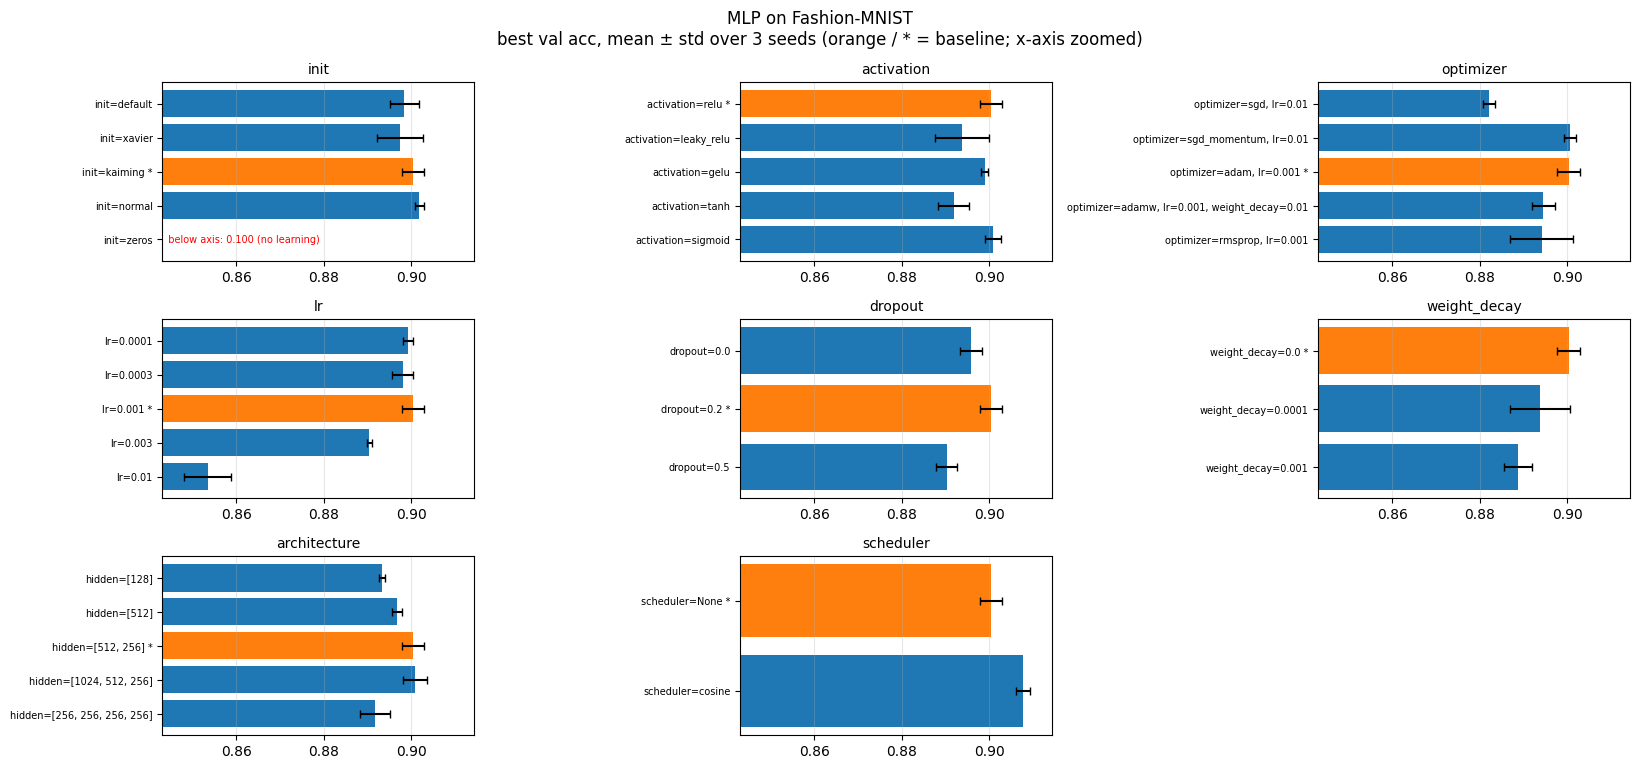

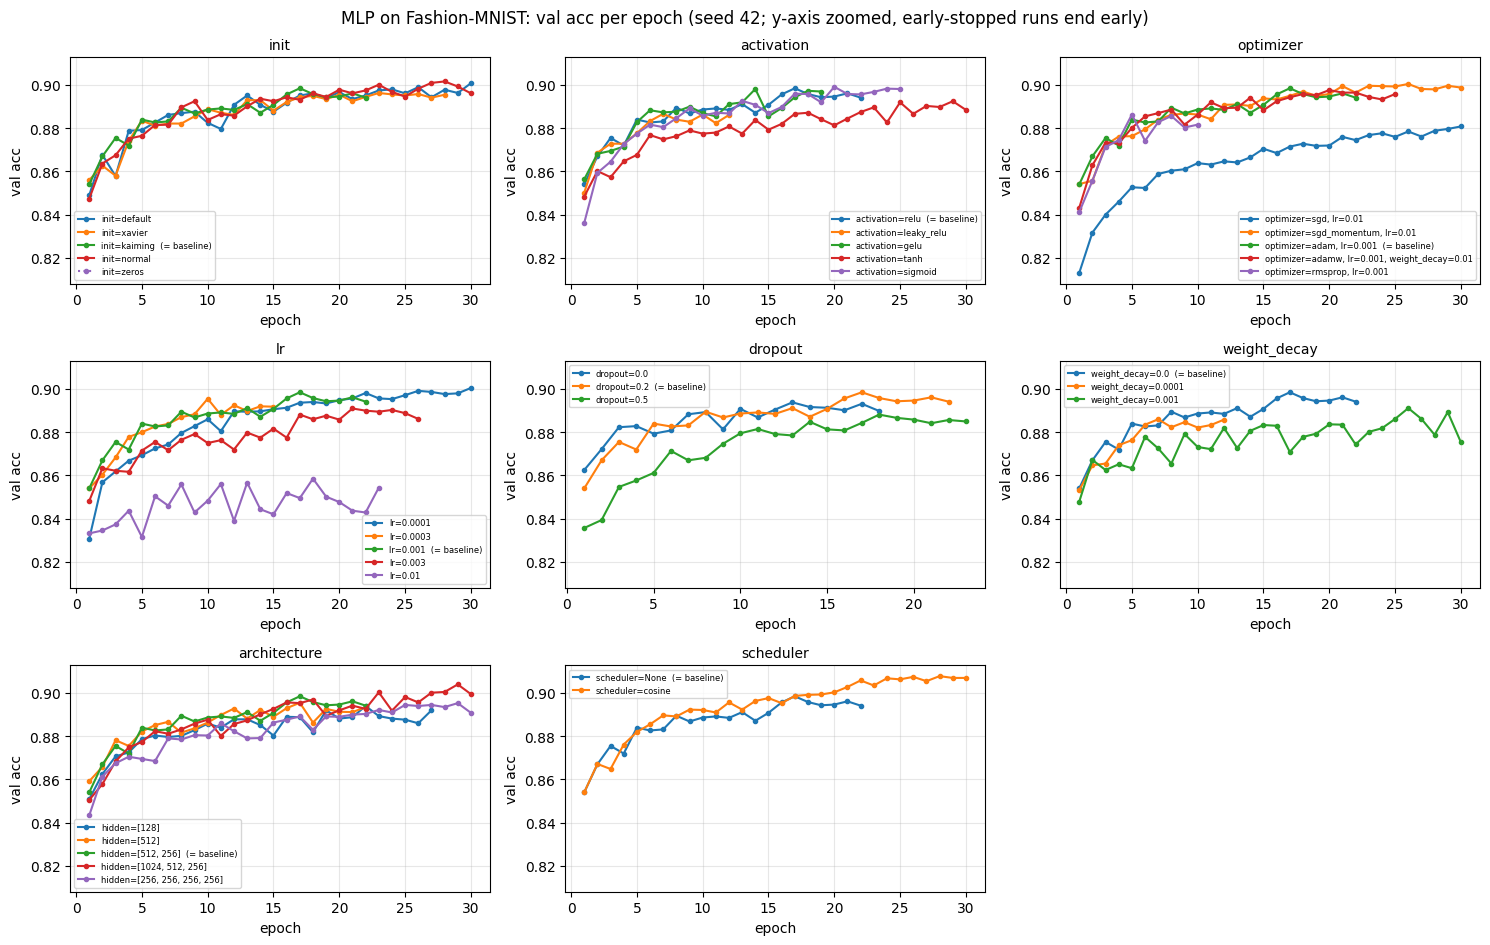

,model,group,setting,val_mean,val_std,best_epoch,epochs_run,train_acc_eval,gap,params,no_learning,diverged
0,mlp,init,init=default,0.8984,0.0033,23.6667,26.6667,0.9525,0.0541,535818,False,False
1,mlp,init,init=xavier,0.8974,0.0052,19.6667,24.3333,0.9429,0.0455,535818,False,False
2,mlp,init,init=kaiming (= baseline),0.9004,0.0026,20.0000,25.0000,0.9471,0.0467,535818,False,False
3,mlp,init,init=normal,0.9018,0.0010,24.3333,28.3333,0.9568,0.0550,535818,False,False
4,mlp,init,init=zeros,0.1002,0.0013,3.3333,8.3333,0.1000,-0.0002,535818,True,False
5,mlp,activation,activation=relu (= baseline),0.9004,0.0026,20.0000,25.0000,0.9471,0.0467,535818,False,False
6,mlp,activation,activation=leaky_relu,0.8938,0.0062,13.0000,18.0000,0.9315,0.0377,535818,False,False
7,mlp,activation,activation=gelu,0.8989,0.0008,20.0000,25.0000,0.9506,0.0517,535818,False,False
8,mlp,activation,activation=tanh,0.8918,0.0035,24.3333,27.6667,0.9305,0.0386,535818,False,False
9,mlp,activation,activation=sigmoid,0.9009,0.0018,25.0000,28.3333,0.9597,0.0588,535818,False,False


In [ ]:
mlp_df = run_sweep(MLP_BASE, MLP_VARIATIONS, fmnist, "mlp")
mlp_df.to_csv(f"{OUT_DIR}/fmnist_mlp_sweep.csv", index=False)
plot_sweep_bars(mlp_df, "MLP on Fashion-MNIST").savefig(f"{OUT_DIR}/fmnist_mlp_bars.png", dpi=150)
plt.show()
plot_sweep_curves(mlp_df, "fashion_mnist", "MLP on Fashion-MNIST").savefig(f"{OUT_DIR}/fmnist_mlp_curves.png", dpi=150)
plt.show()
mlp_df[SWEEP_COLS].round(4)

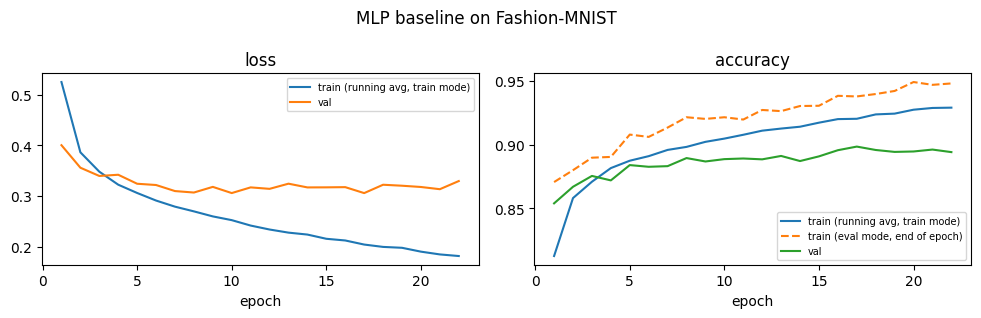

In [ ]:
plot_history(STORE[run_key(MLP_BASE, "fashion_mnist", MAX_EPOCHS, PATIENCE, SWEEP_SEEDS[0])]["hist"],
             "MLP baseline on Fashion-MNIST").savefig(f"{OUT_DIR}/fmnist_mlp_baseline_curves.png", dpi=150)
plt.show()

### 5b. CNN

cnn: 35 settings, 26 unique configs
cnn: 26 unique configs x 3 seeds -> 78 runs still to do
[cnn   1/78] seed 42 val=0.9322 (best ep 24/29) | 0.7 min, ETA 54.7 min
[cnn   2/78] seed 43 val=0.9330 (best ep 28/30) | 1.4 min, ETA 54.2 min
[cnn   3/78] seed 44 val=0.9297 (best ep 16/21) | 1.9 min, ETA 48.3 min
[cnn   4/78] seed 42 val=0.9288 (best ep 12/17) | 2.3 min, ETA 43.2 min
[cnn   5/78] seed 43 val=0.9277 (best ep 13/18) | 2.8 min, ETA 40.4 min
[cnn   6/78] seed 44 val=0.9282 (best ep 16/21) | 3.3 min, ETA 39.2 min
[cnn   7/78] seed 42 val=0.9232 (best ep 11/16) | 3.7 min, ETA 37.0 min
[cnn   8/78] seed 43 val=0.9305 (best ep 26/30) | 4.4 min, ETA 38.2 min
[cnn   9/78] seed 44 val=0.9277 (best ep 20/25) | 5.0 min, ETA 38.1 min
[cnn  10/78] seed 42 val=0.9300 (best ep 27/30) | 5.7 min, ETA 38.6 min
[cnn  11/78] seed 43 val=0.9268 (best ep 27/30) | 6.4 min, ETA 39.0 min
[cnn  12/78] seed 44 val=0.9270 (best ep 24/29) | 7.1 min, ETA 39.0 min
[cnn  13/78] seed 42 val=0.9280 (best ep 18/

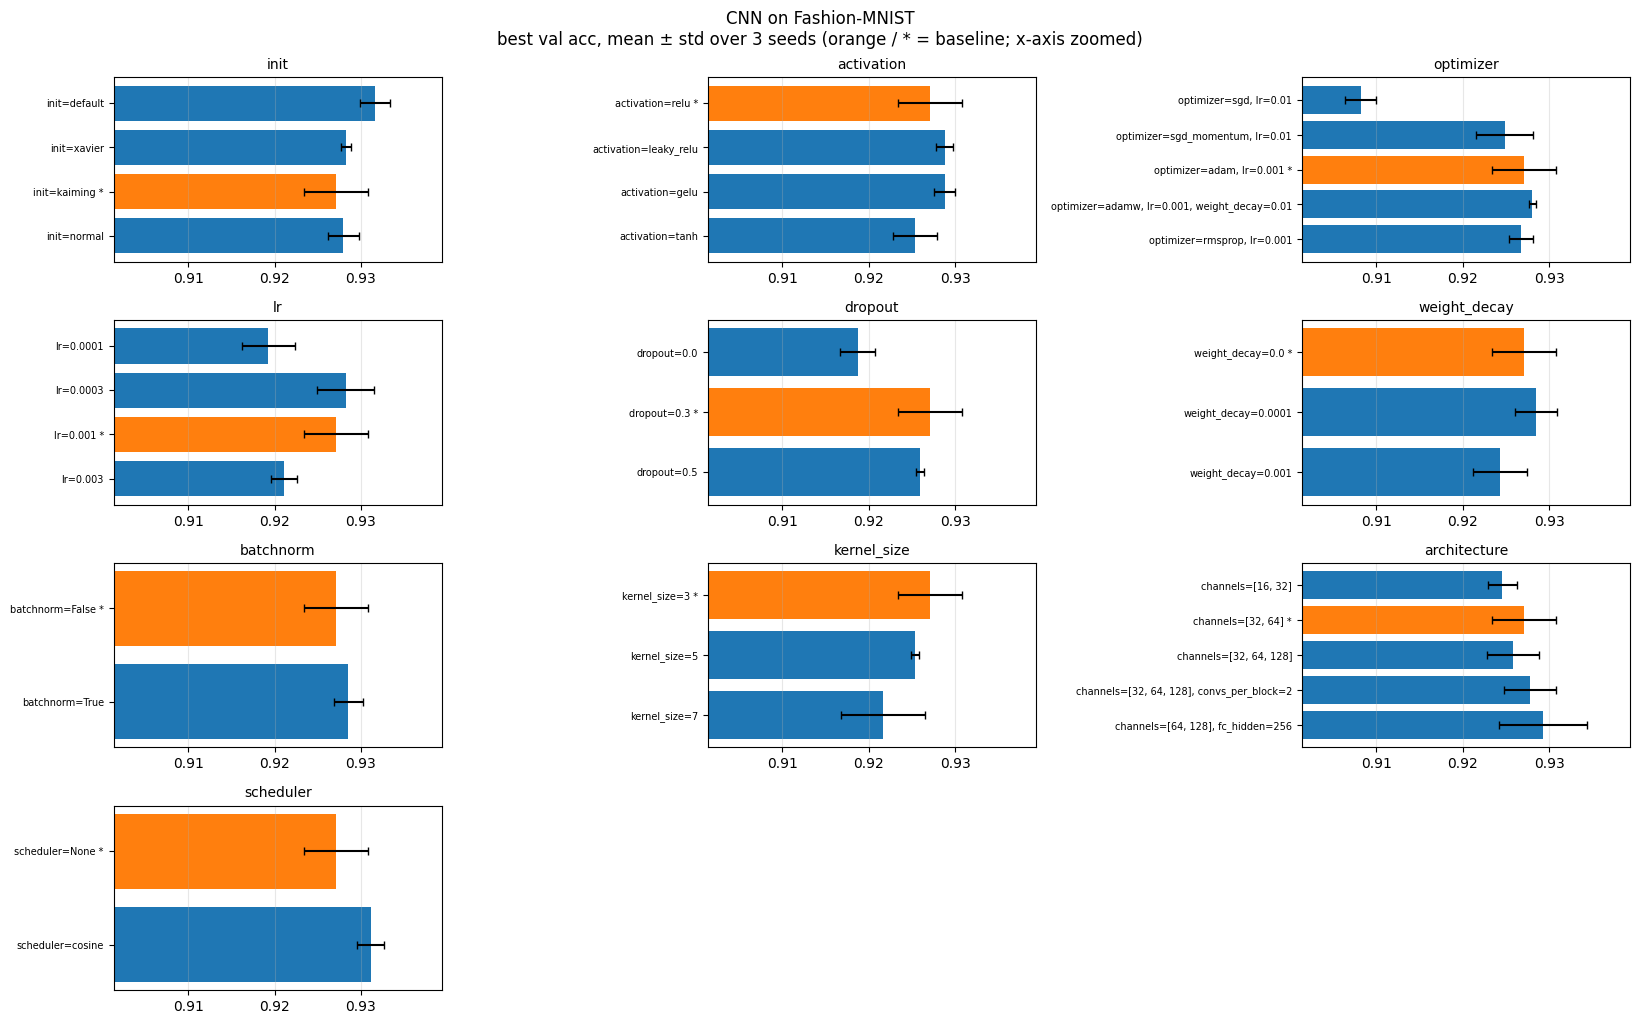

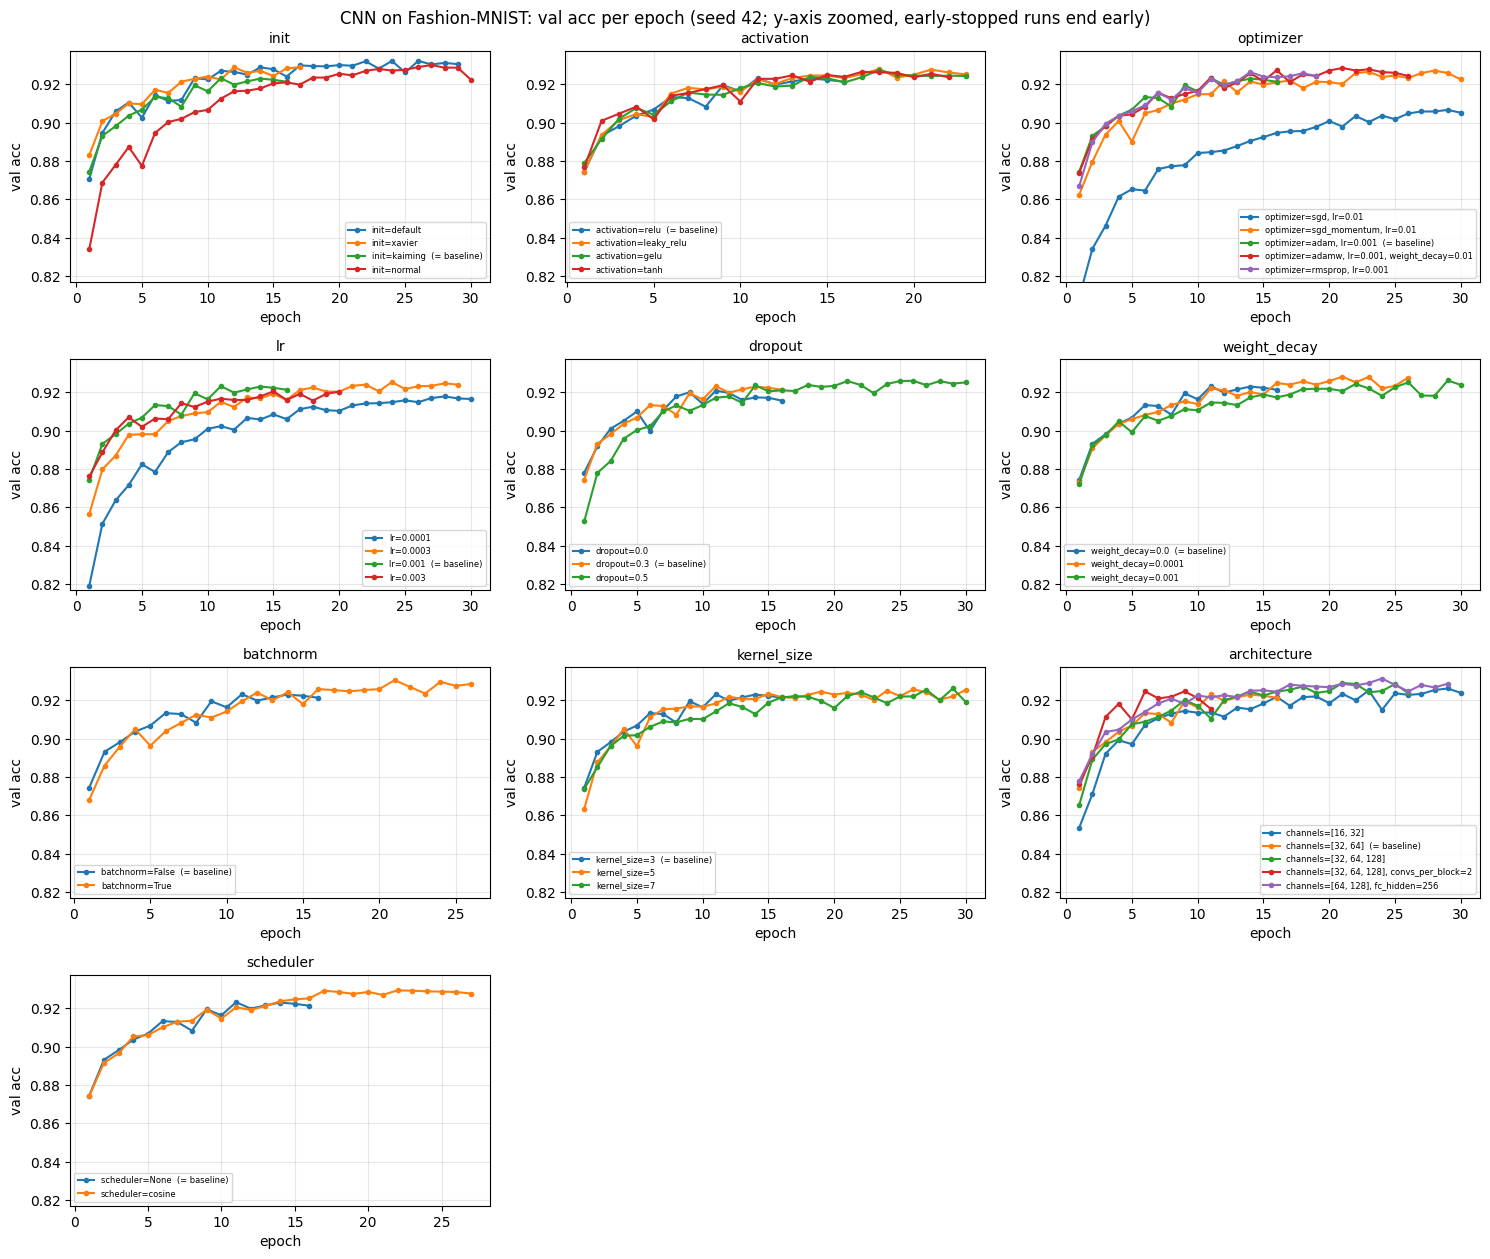

,model,group,setting,val_mean,val_std,best_epoch,epochs_run,train_acc_eval,gap,params,no_learning,diverged
0,cnn,init,init=default,0.9316,0.0017,22.6667,26.6667,0.9843,0.0527,421642,False,False
1,cnn,init,init=xavier,0.9282,0.0006,13.6667,18.6667,0.9710,0.0428,421642,False,False
2,cnn,init,init=kaiming (= baseline),0.9271,0.0037,19.0000,23.6667,0.9722,0.0451,421642,False,False
3,cnn,init,init=normal,0.9279,0.0018,26.0000,29.6667,0.9724,0.0445,421642,False,False
4,cnn,activation,activation=relu (= baseline),0.9271,0.0037,19.0000,23.6667,0.9722,0.0451,421642,False,False
5,cnn,activation,activation=leaky_relu,0.9288,0.0009,19.0000,24.0000,0.9831,0.0543,421642,False,False
6,cnn,activation,activation=gelu,0.9288,0.0012,17.0000,22.0000,0.9856,0.0569,421642,False,False
7,cnn,activation,activation=tanh,0.9254,0.0025,14.6667,19.6667,0.9672,0.0418,421642,False,False
8,cnn,optimizer,"optimizer=sgd, lr=0.01",0.9082,0.0018,29.6667,30.0000,0.9262,0.0180,421642,False,False
9,cnn,optimizer,"optimizer=sgd_momentum, lr=0.01",0.9248,0.0033,21.3333,25.3333,0.9632,0.0384,421642,False,False


In [ ]:
cnn_df = run_sweep(CNN_BASE, CNN_VARIATIONS, fmnist, "cnn")
cnn_df.to_csv(f"{OUT_DIR}/fmnist_cnn_sweep.csv", index=False)
plot_sweep_bars(cnn_df, "CNN on Fashion-MNIST").savefig(f"{OUT_DIR}/fmnist_cnn_bars.png", dpi=150)
plt.show()
plot_sweep_curves(cnn_df, "fashion_mnist", "CNN on Fashion-MNIST").savefig(f"{OUT_DIR}/fmnist_cnn_curves.png", dpi=150)
plt.show()
cnn_df[SWEEP_COLS].round(4)

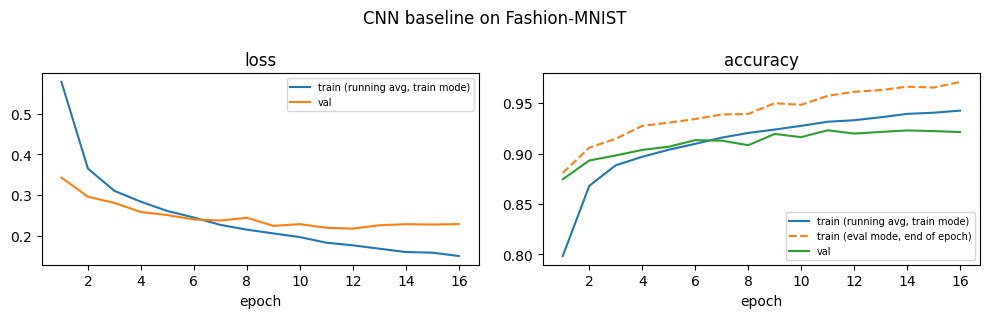

In [ ]:
plot_history(STORE[run_key(CNN_BASE, "fashion_mnist", MAX_EPOCHS, PATIENCE, SWEEP_SEEDS[0])]["hist"],
             "CNN baseline on Fashion-MNIST").savefig(f"{OUT_DIR}/fmnist_cnn_baseline_curves.png", dpi=150)
plt.show()

### 5c. Combining the best value of each factor
The one-factor-at-a-time sweep ignores interactions, so we also try one config that combines the best value of every group (by mean val acc). Optimizer, lr and weight decay interact strongly. If the best optimizer is not the baseline optimizer, its own lr/wd are kept and the lr/wd groups are ignored. If the combined config equals a config that already ran (e.g. the baseline), nothing new is trained and the notebook says so.

In [ ]:
def combine_best(base, df):
    best = {g: CFG_BY_ID[sub.sort_values("val_mean", ascending=False).iloc[0]["cfg_id"]]
            for g, sub in df.groupby("group")}
    cfg = dict(base)
    for g, c in best.items():
        if g not in ("optimizer", "lr", "weight_decay"):
            cfg.update({k: v for k, v in c.items() if base.get(k) != v})
    opt_cfg = best.get("optimizer", base)
    if opt_cfg["optimizer"] == base["optimizer"]:
        if "lr" in best:
            cfg["lr"] = best["lr"]["lr"]
        if "weight_decay" in best:
            cfg["weight_decay"] = best["weight_decay"]["weight_decay"]
    else:
        cfg.update(optimizer=opt_cfg["optimizer"], lr=opt_cfg["lr"], weight_decay=opt_cfg["weight_decay"])
    return cfg


def add_combined(base, df, data, model_name):
    cfg = combine_best(base, df)
    cid = cfg_id(cfg)
    changes = {k: v for k, v in cfg.items() if base.get(k) != v}
    if cid in set(df["cfg_id"]):
        same = df[df["cfg_id"] == cid].iloc[0]
        print(f"{model_name}: combined config {changes or '(no changes)'} is identical to "
              f"'{same['group']}: {same['setting']}' -> nothing new to train.")
        return df
    CFG_BY_ID[cid] = cfg
    train_configs([cfg], data, MAX_EPOCHS, PATIENCE, SWEEP_SEEDS, f"{model_name}-combined")
    row = {"model": model_name, "group": "combined", "setting": describe(changes), "cfg_id": cid,
           "is_baseline": False, **aggregate(cfg, data["name"], MAX_EPOCHS, PATIENCE, SWEEP_SEEDS)}
    base_val = df[df["is_baseline"]]["val_mean"].iloc[0]
    print(f"{model_name} combined ({describe(changes)}): val {row['val_mean']:.4f} ± {row['val_std']:.4f} "
          f"vs baseline {base_val:.4f}")
    return pd.concat([df, pd.DataFrame([row])], ignore_index=True)


mlp_df = add_combined(MLP_BASE, mlp_df, fmnist, "mlp")
cnn_df = add_combined(CNN_BASE, cnn_df, fmnist, "cnn")
all_fmnist = pd.concat([mlp_df, cnn_df], ignore_index=True)
all_fmnist.to_csv(f"{OUT_DIR}/fmnist_all_configs.csv", index=False)

mlp-combined: 1 unique configs x 3 seeds -> 3 runs still to do
[mlp-combined   1/3] seed 42 val=0.7558 (best ep 30/30) | 0.4 min, ETA 0.8 min
[mlp-combined   2/3] seed 43 val=0.7555 (best ep 27/30) | 0.8 min, ETA 0.4 min
[mlp-combined   3/3] seed 44 val=0.7532 (best ep 25/30) | 1.2 min, ETA 0.0 min
mlp combined (hidden=[1024, 512, 256], activation=sigmoid, init=normal, optimizer=sgd_momentum, lr=0.01, scheduler=cosine): val 0.7548 ± 0.0015 vs baseline 0.9004
cnn-combined: 1 unique configs x 3 seeds -> 3 runs still to do
[cnn-combined   1/3] seed 42 val=0.9390 (best ep 18/23) | 1.5 min, ETA 3.0 min
[cnn-combined   2/3] seed 43 val=0.9390 (best ep 26/30) | 3.5 min, ETA 1.8 min
[cnn-combined   3/3] seed 44 val=0.9382 (best ep 19/24) | 5.1 min, ETA 0.0 min
cnn combined (channels=[64, 128], fc_hidden=256, activation=leaky_relu, batchnorm=True, init=default, optimizer=adamw, weight_decay=0.01, scheduler=cosine): val 0.9387 ± 0.0005 vs baseline 0.9271


## 6. Selection: top-k per model type → Fashion-MNIST test results
Duplicate configs are removed, then the **top-k MLPs and top-k CNNs** are chosen by mean validation accuracy, so both model types reach CIFAR-10. The column `overall_rank` gives the overall top 3 that the assignment asks for. Test accuracy is shown here for the first time (mean ± std over the sweep seeds).

In [ ]:
unique = all_fmnist.drop_duplicates("cfg_id")
unique = unique[~unique["no_learning"] & ~unique["diverged"]].sort_values("val_mean", ascending=False)
selected = pd.concat([unique[unique["model"] == m].head(TOP_K_PER_MODEL) for m in ["mlp", "cnn"]],
                     ignore_index=True)
selected["label"] = [f"{m.upper()}-{i + 1}" for m, i in
                     zip(selected["model"], selected.groupby("model").cumcount())]
overall = {cid: i + 1 for i, cid in enumerate(unique["cfg_id"].head(3))}
selected["overall_rank"] = selected["cfg_id"].map(overall).astype("Int64")

fmnist_final = selected[["label", "overall_rank", "group", "setting", "val_mean", "val_std",
                         "test_mean", "test_std", "best_epoch", "gap", "params"]].rename(
    columns={"val_mean": "fmnist_val", "val_std": "fmnist_val_std",
             "test_mean": "fmnist_test", "test_std": "fmnist_test_std"})
fmnist_final.to_csv(f"{OUT_DIR}/fmnist_selected_test.csv", index=False)
fmnist_final.round(4)

,label,overall_rank,group,setting,fmnist_val,fmnist_val_std,fmnist_test,fmnist_test_std,best_epoch,gap,params
0,MLP-1,<NA>,scheduler,scheduler=cosine,0.9077,0.0017,0.9026,0.0015,25.3333,0.0644,535818
1,MLP-2,<NA>,init,init=normal,0.9018,0.0010,0.8963,0.0023,24.3333,0.0550,535818
2,MLP-3,<NA>,activation,activation=sigmoid,0.9009,0.0018,0.8955,0.0024,25.0000,0.0588,535818
3,CNN-1,1,combined,"channels=[64, 128], fc_hidden=256, activation=...",0.9387,0.0005,0.9321,0.0011,21.0000,0.0525,1683338
4,CNN-2,2,init,init=default,0.9316,0.0017,0.9244,0.0022,22.6667,0.0527,421642
5,CNN-3,3,scheduler,scheduler=cosine,0.9311,0.0016,0.9274,0.0013,24.3333,0.0551,421642


## 7. The selected setups on CIFAR-10
Same hyperparameters on 3×32×32 colour images (the models adapt their input layer automatically). There are more epochs and a longer patience, because CIFAR-10 converges more slowly. Results are mean ± std over `FINAL_SEEDS` and are also stored in `runs.jsonl`, so a disconnect does not lose them.

In [ ]:
del fmnist
if torch.cuda.is_available():
    torch.cuda.empty_cache()
cifar = load_dataset("cifar10")

cifar10: train (45000, 3, 32, 32), val (5000, 3, 32, 32), test (10000, 3, 32, 32), classes=10 (6s)
  normalisation check (train): per-channel mean [0. 0. 0.], std [1. 1. 1.]


In [ ]:
sel_cfgs = [CFG_BY_ID[c] for c in selected["cfg_id"]]
train_configs(sel_cfgs, cifar, CIFAR_MAX_EPOCHS, CIFAR_PATIENCE, FINAL_SEEDS, "cifar10")

cifar_rows = []
for (_, r), cfg in zip(selected.iterrows(), sel_cfgs):
    a = aggregate(cfg, "cifar10", CIFAR_MAX_EPOCHS, CIFAR_PATIENCE, FINAL_SEEDS)
    cifar_rows.append({"label": r["label"], "cifar_val": a["val_mean"], "cifar_val_std": a["val_std"],
                       "cifar_test": a["test_mean"], "cifar_test_std": a["test_std"],
                       "cifar_best_epoch": a["best_epoch"], "cifar_gap": a["gap"]})
comparison = fmnist_final.merge(pd.DataFrame(cifar_rows), on="label")
comparison["test_drop"] = comparison["fmnist_test"] - comparison["cifar_test"]
comparison.to_csv(f"{OUT_DIR}/fmnist_vs_cifar.csv", index=False)
comparison[["label", "overall_rank", "group", "setting", "params", "fmnist_test", "fmnist_test_std",
            "cifar_test", "cifar_test_std", "test_drop", "gap", "cifar_gap", "cifar_best_epoch"]].round(4)

cifar10: 6 unique configs x 3 seeds -> 18 runs still to do
[cifar10   1/18] seed 42 val=0.5786 (best ep 49/50) | 0.5 min, ETA 9.3 min
[cifar10   2/18] seed 43 val=0.5738 (best ep 45/50) | 1.1 min, ETA 8.6 min
[cifar10   3/18] seed 44 val=0.5706 (best ep 46/50) | 1.6 min, ETA 8.1 min
[cifar10   4/18] seed 42 val=0.5496 (best ep 19/27) | 1.9 min, ETA 6.7 min
[cifar10   5/18] seed 43 val=0.5496 (best ep 18/26) | 2.2 min, ETA 5.7 min
[cifar10   6/18] seed 44 val=0.5454 (best ep 22/30) | 2.5 min, ETA 5.0 min
[cifar10   7/18] seed 42 val=0.5446 (best ep 34/42) | 3.0 min, ETA 4.6 min
[cifar10   8/18] seed 43 val=0.5442 (best ep 44/50) | 3.5 min, ETA 4.4 min
[cifar10   9/18] seed 44 val=0.5476 (best ep 37/45) | 4.0 min, ETA 4.0 min
[cifar10  10/18] seed 42 val=0.8138 (best ep 50/50) | 7.3 min, ETA 5.8 min
[cifar10  11/18] seed 43 val=0.8088 (best ep 50/50) | 10.6 min, ETA 6.7 min
[cifar10  12/18] seed 44 val=0.8118 (best ep 41/49) | 13.8 min, ETA 6.9 min
[cifar10  13/18] seed 42 val=0.7648 (be

,label,overall_rank,group,setting,params,fmnist_test,fmnist_test_std,cifar_test,cifar_test_std,test_drop,gap,cifar_gap,cifar_best_epoch
0,MLP-1,<NA>,scheduler,scheduler=cosine,535818,0.9026,0.0015,0.5638,0.0024,0.3388,0.0644,0.3249,46.6667
1,MLP-2,<NA>,init,init=normal,535818,0.8963,0.0023,0.5427,0.0034,0.3536,0.0550,0.2082,19.6667
2,MLP-3,<NA>,activation,activation=sigmoid,535818,0.8955,0.0024,0.5351,0.0032,0.3604,0.0588,0.2512,38.3333
3,CNN-1,1,combined,"channels=[64, 128], fc_hidden=256, activation=...",1683338,0.9321,0.0011,0.8074,0.0013,0.1247,0.0525,0.1884,47.0000
4,CNN-2,2,init,init=default,421642,0.9244,0.0022,0.7443,0.0029,0.1801,0.0527,0.1944,25.0000
5,CNN-3,3,scheduler,scheduler=cosine,421642,0.9274,0.0013,0.7492,0.0040,0.1781,0.0551,0.2243,46.6667


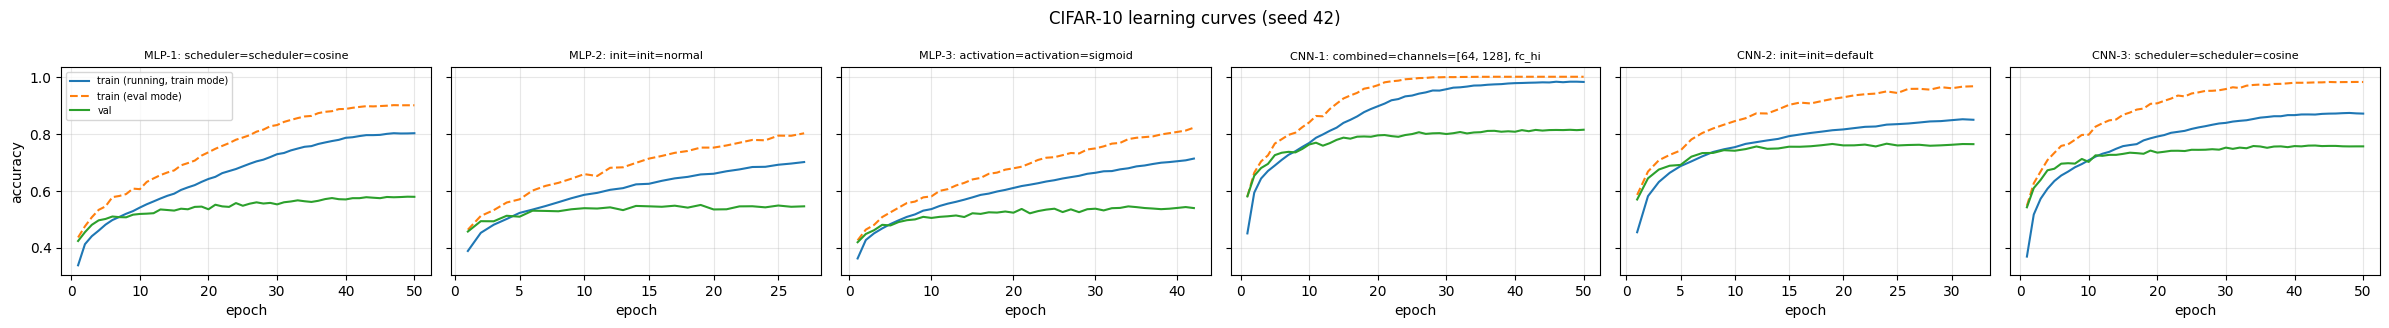

In [ ]:
# CIFAR-10 learning curves (first seed). The gap between the eval-mode train curve and val shows overfitting.
n = len(selected)
fig, axes = plt.subplots(1, n, figsize=(4 * n, 3.3), squeeze=False, sharey=True)
for ax, (_, r), cfg in zip(axes.flat, selected.iterrows(), sel_cfgs):
    h = STORE[run_key(cfg, "cifar10", CIFAR_MAX_EPOCHS, CIFAR_PATIENCE, FINAL_SEEDS[0])]["hist"]
    ep = range(1, len(h["val_acc"]) + 1)
    ax.plot(ep, h["train_acc"], label="train (running, train mode)")
    ax.plot(ep, h["train_acc_eval"], "--", label="train (eval mode)")
    ax.plot(ep, h["val_acc"], label="val")
    ax.set_title(f"{r['label']}: {r['group']}={r['setting'][:25]}", fontsize=8)
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
axes.flat[0].set_ylabel("accuracy"); axes.flat[0].legend(fontsize=7)
fig.suptitle(f"CIFAR-10 learning curves (seed {FINAL_SEEDS[0]})")
plt.tight_layout()
fig.savefig(f"{OUT_DIR}/cifar_curves.png", dpi=150)
plt.show()

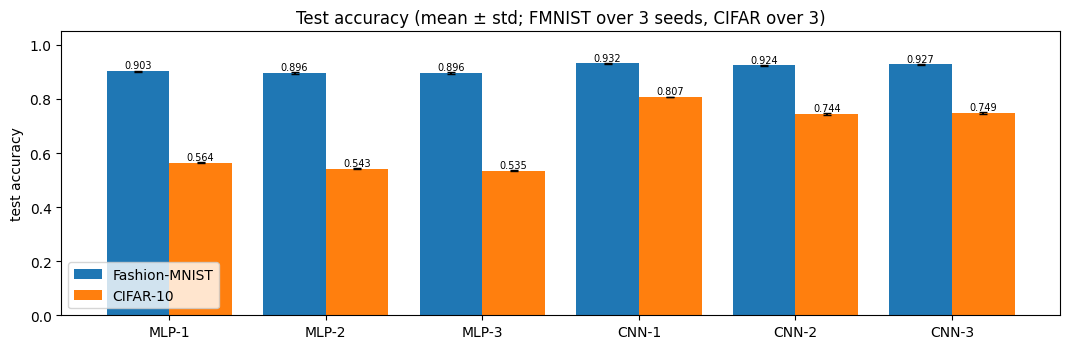

In [ ]:
# Fashion-MNIST vs CIFAR-10 test accuracy, mean ± std over seeds
fig, ax = plt.subplots(figsize=(1.3 * n + 3, 3.6))
xpos = np.arange(n)
ax.bar(xpos - 0.2, comparison["fmnist_test"], 0.4, yerr=comparison["fmnist_test_std"].fillna(0),
       capsize=3, label="Fashion-MNIST")
ax.bar(xpos + 0.2, comparison["cifar_test"], 0.4, yerr=comparison["cifar_test_std"].fillna(0),
       capsize=3, label="CIFAR-10")
for x, (f_, c_) in zip(xpos, zip(comparison["fmnist_test"], comparison["cifar_test"])):
    ax.text(x - 0.2, f_ + 0.01, f"{f_:.3f}", ha="center", fontsize=7)
    ax.text(x + 0.2, c_ + 0.01, f"{c_:.3f}", ha="center", fontsize=7)
ax.set_xticks(xpos)
ax.set_xticklabels(comparison["label"])
ax.set_ylabel("test accuracy"); ax.set_ylim(0, 1.05); ax.legend(loc="lower left")
ax.set_title(f"Test accuracy (mean ± std; FMNIST over {len(SWEEP_SEEDS)} seeds, CIFAR over {len(FINAL_SEEDS)})")
plt.tight_layout()
fig.savefig(f"{OUT_DIR}/fmnist_vs_cifar.png", dpi=150)
plt.show()

## Notes for the report
* **Noise level**: always compare differences against `val_std`. Differences smaller than about 2 standard deviations across seeds are not meaningful.
* **Init**: `zeros` is flagged `no_learning` and stays at chance. Symmetry is never broken, and with ReLU the hidden-layer gradients are exactly 0. Compare `normal(0.01)` with Kaiming/Xavier, especially for deep MLPs.
* **Activation**: sigmoid/tanh vs the ReLU family (vanishing gradients, convergence speed → look at `best_epoch`).
* **Optimizer / lr**: plain SGD at lr 1e-2 converges slowly. Adam with lr 1e-2 is unstable.
* **Regularisation**: compare `gap` (eval-mode train acc − val acc at the best epoch) with and without dropout / weight decay.
* **Train vs val curves**: the running train accuracy is averaged over the epoch in train mode (dropout on, weights still improving), so early on it is below val. The eval-mode train curve is the fair comparison.
* **Initial loss above ln(10) ≈ 2.30**: Kaiming init on the output layer gives logits with std ≈ √2, so the expected initial cross-entropy is ≈ 3. Combined with the running average over the first epoch, this explains epoch-1 losses around 2.5–3. The normalisation check printed in section 1 confirms the inputs are standardised.
* **CIFAR-10**: MLPs drop much more than CNNs. Flattening throws away spatial structure, translation invariance is lost, and the first layer has 3072 inputs, so it has many more parameters and overfits (`cifar_gap`). Fashion-MNIST is centred, grayscale and has no background clutter, so settings that are "good enough" there do not have to transfer.

All CSVs, figures and `runs.jsonl` are in `OUT_DIR`.